<a href="https://colab.research.google.com/github/bsheese/cs377/blob/main/18_classification/18_6_Ensemble/18_6_3_Boosting_and_BART.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Boosting and BART: Sequential Learning

---

## Introduction

In the previous notebook, we saw how bagging and random forests reduce **variance** by averaging many independent trees. Boosting takes a different approach: it reduces **bias** by building trees sequentially, where each new tree corrects the errors of the ensemble so far.

Recall from 17_2_2: Random Forests train trees in parallel (independent), while Boosting trains trees sequentially (each one learns from the previous). This often lets boosting fit the data more closely, but it also makes boosting more prone to overfitting if it is not carefully controlled.

### Learning Objectives
By the end of this notebook, you will be able to:
1. Implement AdaBoost and Gradient Boosting classifiers.
2. Understand the difference between adaptive boosting (reweighting) and gradient boosting (residuals).
3. Tune boosting hyperparameters using GridSearchCV.
4. Compare boosting to bagging and random forests using classification metrics.
5. Understand the concept of BART (Bayesian Additive Regression Trees) and its uncertainty quantification.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.ensemble import (
    AdaBoostClassifier, GradientBoostingClassifier,
    RandomForestClassifier, BaggingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc
)

sns.set_context("talk")
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

# Flip target: 1=malignant, 0=benign (matching original UCI encoding)
y = 1 - y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Class distribution after flip: {y_test.mean():.1%} malignant (1), {(1-y_test.mean()):.1%} benign (0)")

Class distribution after flip: 37.4% malignant (1), 62.6% benign (0)


---
## 1. AdaBoost: Adaptive Boosting

AdaBoost is the original boosting algorithm. It works by:

1. Starting with equal weights for all training samples.
2. Training a weak learner (typically a shallow tree, or "stump").
3. Increasing the weights of misclassified samples so the next tree focuses on them.
4. Repeating for a fixed number of trees.
5. Combining all trees with weighted voting (better trees get more weight).

This is similar to a tutor giving extra attention to the problems a student keeps getting wrong.

### Why Stumps (max_depth=1)?

AdaBoost uses decision stumps (trees with a single split) as base learners. This might seem too simple to be useful, but AdaBoost is designed around exactly this kind of model. Stumps are *weak learners* that are only slightly better than random guessing, and AdaBoost gets its accuracy from combining hundreds of them, each focusing on different hard-to-classify samples. If we used deep trees instead, each one would already be quite strong, and there would be little room for the sequential correction process to add value. Deep trees in boosting also overfit much faster.

This contrasts with bagging (18_6_2), where we used *deep* trees. Bagging averages many overfitting trees to cancel their individual errors. Boosting builds weak trees sequentially, each one correcting the previous ensemble's mistakes. The two methods use different kinds of trees because they are aimed at different problems: bagging mainly reduces variance, and boosting mainly reduces bias.

In [3]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=200,
    learning_rate=1.0,
    random_state=42
)
ada.fit(X_train, y_train)

y_pred_ada = ada.predict(X_test)
y_proba_ada = ada.predict_proba(X_test)[:, 1]

print(f"AdaBoost Accuracy:          {accuracy_score(y_test, y_pred_ada):.3f}")
print(f"AdaBoost F1 Score:          {f1_score(y_test, y_pred_ada):.3f}")
print(f"AdaBoost Malignant Recall:  {recall_score(y_test, y_pred_ada):.3f}")

AdaBoost Accuracy:          0.977
AdaBoost F1 Score:          0.968
AdaBoost Malignant Recall:  0.938


---
## 2. Gradient Boosting: Predicting the Residuals

Gradient Boosting is a more general approach than AdaBoost. Instead of reweighting samples, it:

1. Starts with a simple prediction (the log-odds of the positive class).
2. Calculates the residuals (errors) of the current ensemble.
3. Trains a new tree to predict these residuals.
4. Adds the tree's predictions to the ensemble, scaled by the learning rate.
5. Repeats for a fixed number of trees.

Each new tree reduces some of the error that remains after the previous trees. This is the same idea we saw in 17_2_2 with the Ames Housing data.

### Key Hyperparameters
- **n_estimators**: Number of trees. More trees = more capacity but risk of overfitting.
- **learning_rate**: Shrinkage factor. Smaller values = slower learning, need more trees, but often better generalization.
- **max_depth**: Tree complexity. Boosting typically uses shallow trees (depth 3-5).

In [4]:
gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_proba_gb = gb.predict_proba(X_test)[:, 1]

print(f"Gradient Boosting Accuracy:         {accuracy_score(y_test, y_pred_gb):.3f}")
print(f"Gradient Boosting F1 Score:         {f1_score(y_test, y_pred_gb):.3f}")
print(f"Gradient Boosting Malignant Recall: {recall_score(y_test, y_pred_gb):.3f}")

Gradient Boosting Accuracy:         0.965
Gradient Boosting F1 Score:         0.952
Gradient Boosting Malignant Recall: 0.922


---
## 3. Classification Metrics: Full Evaluation

Let's evaluate the Gradient Boosting model using the full metric suite.

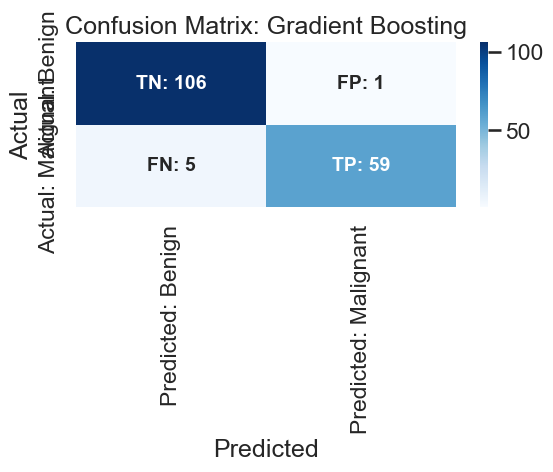


--- Medical Interpretation ---
False Negatives (missed cancers): 5
False Positives (unnecessary biopsies): 1

--- Classification Report ---
               precision    recall  f1-score   support

   Benign (0)       0.95      0.99      0.97       107
Malignant (1)       0.98      0.92      0.95        64

     accuracy                           0.96       171
    macro avg       0.97      0.96      0.96       171
 weighted avg       0.97      0.96      0.96       171



In [5]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_gb)
tn, fp, fn, tp = cm.ravel()

labels = np.array([[f'TN: {tn}', f'FP: {fp}'], [f'FN: {fn}', f'TP: {tp}']])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues',
            annot_kws={'fontsize': 14, 'fontweight': 'bold'},
            xticklabels=['Predicted: Benign', 'Predicted: Malignant'],
            yticklabels=['Actual: Benign', 'Actual: Malignant'], ax=ax)
ax.set(xlabel='Predicted', ylabel='Actual', title='Confusion Matrix: Gradient Boosting')
plt.tight_layout()
plt.show()

print(f"\n--- Medical Interpretation ---")
print(f"False Negatives (missed cancers): {fn}")
print(f"False Positives (unnecessary biopsies): {fp}")
print(f"\n--- Classification Report ---")
print(classification_report(y_test, y_pred_gb, target_names=['Benign (0)', 'Malignant (1)']))

### ROC Curve

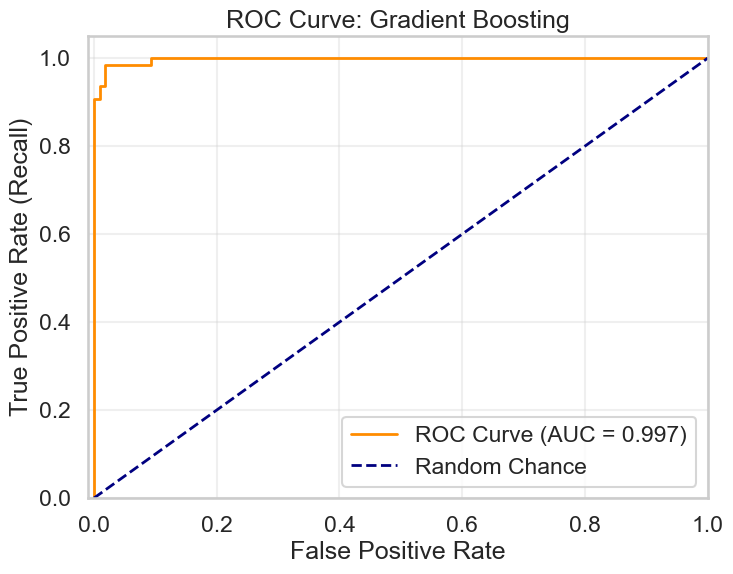

In [6]:
fpr, tpr, _ = roc_curve(y_test, y_proba_gb)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr, y=tpr, estimator=None, sort=False, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve: Gradient Boosting')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

---
## 4. Hyperparameter Tuning with GridSearchCV

Boosting is more sensitive to hyperparameters than random forests. Let's tune the key parameters.

**Runtime note:** This cell tests 27 hyperparameter combinations across 5 folds (135 model fits). It may take 30-60 seconds.

In [7]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 4]
}

grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV F1 Score: {grid_search.best_score_:.4f}")

best_gb = grid_search.best_estimator_
tuned_acc = accuracy_score(y_test, best_gb.predict(X_test))
tuned_recall = recall_score(y_test, best_gb.predict(X_test))
print(f"\nTuned GB Test Accuracy:         {tuned_acc:.3f}")
print(f"Tuned GB Malignant Recall:      {tuned_recall:.3f}")

# Compare with default
default_acc = accuracy_score(y_test, gb.predict(X_test))
default_recall = recall_score(y_test, gb.predict(X_test))
print(f"\nDefault GB (200 trees) Accuracy:  {default_acc:.3f}")
print(f"Default GB (200 trees) Recall:    {default_recall:.3f}")
print(f"\nNote: The tuned model uses {grid_search.best_params_['n_estimators']} trees with learning_rate={grid_search.best_params_['learning_rate']}.")
print(f"The shrinkage trade-off: smaller learning rates need more trees but often generalize better.")

Best Parameters: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300}
Best CV F1 Score: 0.9514

Tuned GB Test Accuracy:         0.971
Tuned GB Malignant Recall:      0.922

Default GB (200 trees) Accuracy:  0.965
Default GB (200 trees) Recall:    0.922

Note: The tuned model uses 300 trees with learning_rate=0.05.
The shrinkage trade-off: smaller learning rates need more trees but often generalize better.


---
## 5. Comparing All Methods

Let's compare AdaBoost, Gradient Boosting, Random Forest, and a single tree using 10-fold cross-validation. This time we include **malignant recall**, which is the most clinically relevant metric.

In [8]:
models = {
    "Single Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)
}

kf = KFold(n_splits=10, shuffle=True, random_state=42)

print(f"{'Model':<25} | {'Mean Acc':<10} | {'Std Dev':<10} | {'Mean F1':<10} | {'Mean Recall':<12} | {'Mean AUC':<10}")
print("-" * 90)

for name, model in models.items():
    acc_scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
    f1_scores = cross_val_score(model, X, y, cv=kf, scoring='f1')
    recall_scores = cross_val_score(model, X, y, cv=kf, scoring='recall')
    roc_scores = cross_val_score(model, X, y, cv=kf, scoring='roc_auc')
    print(f"{name:<25} | {acc_scores.mean():.4f}     | {acc_scores.std():.4f}     | {f1_scores.mean():.4f}     | {recall_scores.mean():.4f}      | {roc_scores.mean():.4f}")

Model                     | Mean Acc   | Std Dev    | Mean F1    | Mean Recall  | Mean AUC  
------------------------------------------------------------------------------------------


Single Tree               | 0.9350     | 0.0359     | 0.9087     | 0.9095      | 0.9279


Random Forest             | 0.9648     | 0.0111     | 0.9521     | 0.9416      | 0.9926


AdaBoost                  | 0.9701     | 0.0158     | 0.9589     | 0.9417      | 0.9940


Gradient Boosting         | 0.9665     | 0.0216     | 0.9546     | 0.9459      | 0.9911


### Interpreting the Results

- **AdaBoost** has the highest mean accuracy (0.970) and F1 (0.959) on this run, which suggests that sequential error correction works well on this data. Keep in mind, though, that AdaBoost is more sensitive to noisy data and outliers than the other methods, and on messier datasets it often does worse.
- **Gradient Boosting** is close behind and has the highest mean malignant recall, although only by a very small margin (0.946, compared with 0.942 for AdaBoost and Random Forest). In general it is the most flexible and most tunable of the methods we've tested.
- **Random Forest** is competitive and the most stable (lowest standard deviation).
- **Single Tree** has the highest variance, since its performance depends heavily on which samples end up in each fold.

The **malignant recall** column is the most clinically relevant: it tells us what fraction of actual cancers each model catches on average. The AUC scores confirm that all three ensembles discriminate very well between malignant and benign tumors (AUC between 0.991 and 0.994), well above the single tree's 0.928.

### Note on BART

BART (Bayesian Additive Regression Trees) is not included in this comparison because it requires specialized libraries (`pymc`, `bartpy`) that are not part of scikit-learn. We would expect its accuracy to be broadly similar to the other ensembles, and its main advantage is that it provides credible intervals for each prediction.

---
## 6. Probability Calibration

In a medical context, the actual probability values matter, not just the predicted class. If a model says "95% probability of malignancy," a doctor needs to be able to trust that number.

**Calibration** checks whether the predicted probabilities match reality. Among all the tumors a well-calibrated model scores at 0.8, about 80% should turn out to be malignant.

A model can rank tumors very well (high accuracy and AUC) and still produce poorly calibrated probabilities. The three ensembles in this notebook tend to behave differently:

- **AdaBoost** is known for poor calibration. Its scores come from a weighted vote of stumps rather than from a model of probability, and they tend to be pushed toward the middle of the range.
- **Random Forest** probabilities are averages of many trees' votes. Averaging makes it hard to reach exactly 0 or 1, so random forests also tend to pull probabilities somewhat toward the middle, though much less than AdaBoost.
- **Gradient Boosting** in sklearn is trained by minimizing log loss, which rewards accurate probabilities, so it is usually reasonably well calibrated. It often gives probabilities very close to 0 or 1, and when it overfits, those extreme probabilities can be overconfident.

A probability near 0 or 1 is not a calibration problem by itself. It is a problem only when the model is wrong about those cases more often than the probability suggests.

We check all three models below. The test set from earlier has only 171 tumors, and most predictions are near 0 or 1, which would leave only a few tumors in each middle bin of a calibration curve. To get more stable curves, we use 10-fold cross-validation to produce an out-of-fold probability for every tumor in the dataset, and we use quantile bins so that each point on the curve represents about the same number of tumors.

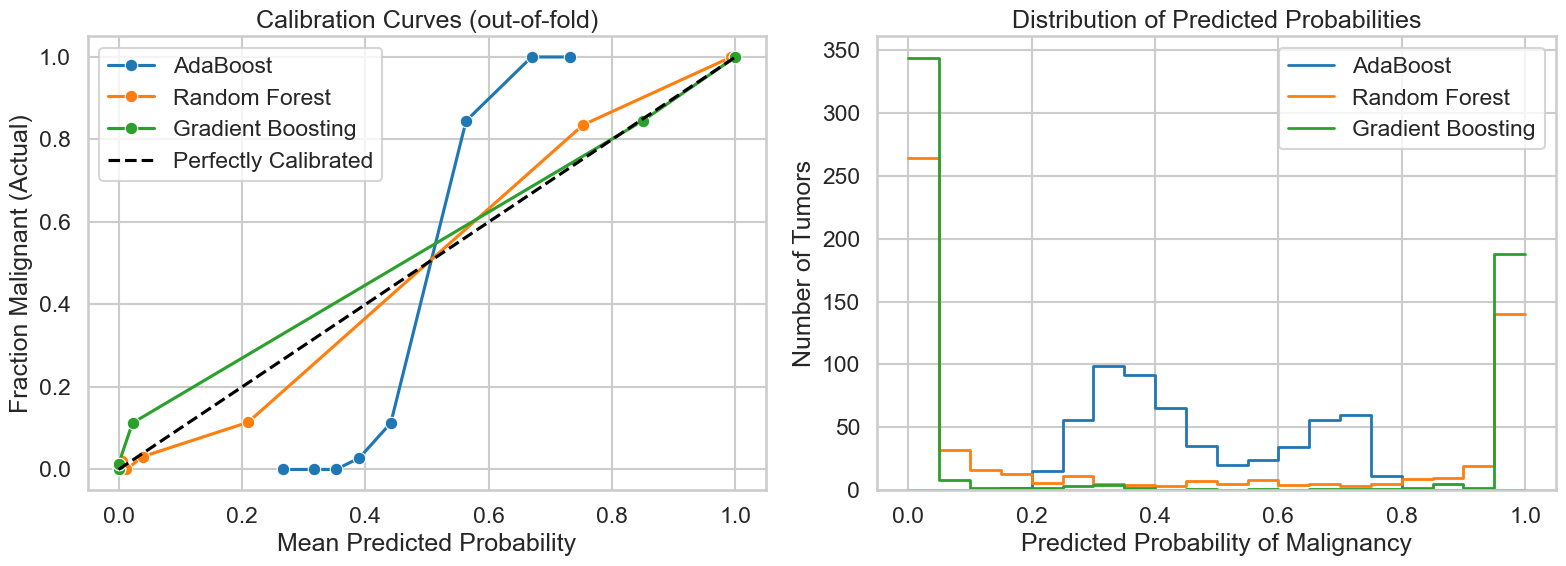

Model               Brier  Min p  Max p   Share below 0.02 or above 0.98
AdaBoost            0.129   0.19   0.78                               0%
Random Forest       0.033   0.00   1.00                              60%
Gradient Boosting   0.031   0.00   1.00                              91%

Brier score is the mean squared difference between predicted probability and outcome (lower is better).
Curves above the diagonal mean the model underestimates probabilities;
curves below the diagonal mean it overestimates them.


In [9]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Out-of-fold probabilities for all 569 tumors. The 171-row test set is too small for a
# calibration curve: most predictions sit near 0 or 1, leaving only a few tumors in each middle bin.
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cal_models = {
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                   n_estimators=200, learning_rate=1.0, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                    max_depth=3, random_state=42),
}
oof_proba = {name: cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]
             for name, model in cal_models.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name, proba in oof_proba.items():
    # Quantile bins put roughly the same number of tumors in each bin
    frac_pos, mean_pred = calibration_curve(y, proba, n_bins=8, strategy='quantile')
    sns.lineplot(x=mean_pred, y=frac_pos, marker='o', estimator=None, sort=False, label=name, ax=axes[0])
    sns.histplot(proba, bins=20, binrange=(0, 1), element='step', fill=False, linewidth=2,
                 label=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Fraction Malignant (Actual)')
axes[0].set_title('Calibration Curves (out-of-fold)')
axes[0].legend()
axes[1].set_xlabel('Predicted Probability of Malignancy')
axes[1].set_ylabel('Number of Tumors')
axes[1].set_title('Distribution of Predicted Probabilities')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"{'Model':<18} {'Brier':>6} {'Min p':>6} {'Max p':>6} {'Share below 0.02 or above 0.98':>32}")
for name, proba in oof_proba.items():
    near_ends = np.mean((proba < 0.02) | (proba > 0.98))
    print(f"{name:<18} {brier_score_loss(y, proba):6.3f} {proba.min():6.2f} {proba.max():6.2f} {near_ends:32.0%}")
print("\nBrier score is the mean squared difference between predicted probability and outcome (lower is better).")
print("Curves above the diagonal mean the model underestimates probabilities;")
print("curves below the diagonal mean it overestimates them.")

### Reading the Calibration Results

**AdaBoost** is the clearest case of poor calibration. All of its probabilities fall between about 0.2 and 0.8 (right panel), and its curve on the left is far from the diagonal. Tumors it scores around 0.3 are almost never malignant, and tumors it scores around 0.7 are almost always malignant. Its Brier score is about four times higher than the other two models', even though it had the highest accuracy earlier in this notebook. AdaBoost ranks tumors well, but its outputs should not be read as probabilities of malignancy without recalibration.

**Random Forest** stays fairly close to the diagonal, with a mild pull toward the middle. The bin it scores at about 0.2 is only about 11% malignant, and the bin it scores at about 0.75 is about 84% malignant, so it is slightly under-confident at both ends.

**Gradient Boosting** puts about 90% of tumors below 0.02 or above 0.98, so its probabilities are much more extreme than the Random Forest's. On this dataset those extreme probabilities are mostly correct, and its Brier score is slightly lower than the Random Forest's. A model can be extreme without being miscalibrated.

This is an easy dataset on which all three models classify very accurately, so the differences between Random Forest and Gradient Boosting are small. On harder or noisier data the gaps can be larger, which is why it is worth checking calibration for any model whose probabilities will be shown to a decision-maker. When a model is poorly calibrated, sklearn's `CalibratedClassifierCV` can rescale its probabilities using cross-validation.

### Your Turn

1. The tuned Gradient Boosting model found specific values for `learning_rate` and `n_estimators`. How does this relate to the shrinkage concept? Would a smaller learning rate with more trees likely perform better or worse?
2. Compare the false negative counts: how many cancers did the single tree miss vs. the gradient boosting model? In a clinical setting, is this difference meaningful?
3. If BART were available and gave a 95% credible interval of [60%, 95%] for a particular patient's malignancy probability, how would a doctor's decision differ from a model that just says "malignant"?

## Conclusion

Boosting takes a fundamentally different approach from bagging:

1. **AdaBoost** reweights misclassified samples, so that later trees focus on the hard cases.
2. **Gradient Boosting** predicts residuals, so each tree reduces some of the remaining error.
3. **Hyperparameter tuning matters more** for boosting, because it is more sensitive to its settings than random forests are.
4. **BART** adds Bayesian uncertainty estimates, providing credible intervals alongside predictions.
5. **Calibration** differs across ensembles. AdaBoost's outputs need recalibration before they can be read as probabilities, while Random Forest and Gradient Boosting were reasonably well calibrated on this dataset.

In the final notebook of this series, we'll compare all five methods directly, using nested cross-validation for unbiased performance estimates.